# 01 – Entendimento do negócio e análise exploratória

**Problema 4 – Política e Gestão Pública: planejamento de investimentos municipais**

Este notebook cobre o item 1 do roteiro (análise do negócio), a formulação do problema (item 2) e a análise exploratória da base extraída com `sql/consulta_final.sql`.

**Regra adotada aqui:** as relações entre as variáveis e o IDEB são exploradas **só com a safra 2023**, que é o conjunto de treino. A safra 2025 aparece apenas em checagens de cobertura e de qualidade das features, sem olhar o IDEB, para não contaminar o teste final.

## 1. O problema de negócio

**Quem usa o resultado:** a equipe de gestão pública que planeja o orçamento da educação municipal (secretarias municipais de educação e de planejamento, ou um órgão estadual que apoia os municípios, como no estudo de caso de Goiás).

**Decisão que queremos apoiar:** onde priorizar investimento e acompanhamento na rede municipal dos anos iniciais (1º ao 5º ano).

**Pergunta:** quais características dos municípios estão associadas a um IDEB mais alto ou mais baixo, e qual IDEB seria esperado para um município com determinado perfil?

**Por que anos iniciais e rede municipal:** é a etapa que a prefeitura oferece e financia quase sozinha, então o gasto municipal declarado no Siconfi conversa com esse resultado (diário, Fase 3).

**O que o gestor ganha com o modelo**
1. **Diagnóstico:** quais fatores acompanham as diferenças entre municípios, lembrando que associação não é efeito.
2. **Comparação justa:** em vez de comparar cada município com a média nacional, comparar com o IDEB esperado para municípios de perfil parecido. Um município pobre com IDEB 5,5 pode estar acima do esperado, e um município rico com 6,0 pode estar abaixo.
3. **Priorização:** os municípios muito abaixo do esperado viram candidatos a uma investigação mais detalhada (gestão, formação docente, infraestrutura).

### 1.1 Variáveis consideradas (questão a)

| Grupo | Exemplos na base | O gestor municipal controla? | Papel na análise |
|---|---|---|---|
| Contexto socioeconômico | INSE 2015, PIB per capita, população, % de matrículas rurais | Não, no curto prazo | Controle: separa o peso do contexto do peso da rede |
| Professores e gestão | % de docentes com superior, adequação da formação, regularidade e esforço docente, complexidade de gestão, alunos por turma, horas-aula | Em parte (concurso, formação continuada, lotação) | Alavancas de política educacional |
| Infraestrutura | biblioteca, quadra, laboratórios, internet, saneamento, energia | Sim (investimento de capital) | Alavancas de investimento |
| Gasto | despesa liquidada com ensino fundamental por aluno | Sim (orçamento) | Variável central para o gestor, mas muito ligada ao contexto |
| Escala | matrículas, número de escolas, alunos por docente | Pouco | Controle |

### 1.2 Fatores externos que podem afetar a análise

- **Nível socioeconômico das famílias.** É o fator mais associado ao desempenho escolar e está medido de forma defasada (o INSE disponível é de 2015).
- **Políticas estaduais.** O Ceará mantém desde 2007 o PAIC (alfabetização na idade certa), em colaboração com os municípios, e distribui parte do ICMS municipal conforme resultados educacionais. Políticas desse tipo elevam o IDEB sem aparecer em nenhuma variável municipal da base.
- **Participação no SAEB.** O IDEB só é divulgado quando a participação dos alunos é suficiente, e a composição de quem faz a prova pode variar entre municípios.
- **Pandemia.** Distorceu 2021 (excluído) e pode ter efeitos residuais em 2023.
- **Qualidade da declaração do gasto.** O Siconfi é autodeclarado e há erros de valor e de classificação entre subfunções.
- **Tamanho da rede.** Com poucos alunos avaliados, o IDEB de um município pode variar bastante de uma edição para outra.

## 2. Formulação do problema (questão b)

| Item | Definição |
|---|---|
| Tarefa | Regressão supervisionada |
| Alvo | IDEB dos anos iniciais da rede municipal (escala de 0 a 10) |
| Unidade | Município e ano |
| Treino | IDEB 2023, com validação cruzada KFold (k = 5) |
| Teste fora do tempo | IDEB 2025, avaliado uma única vez no final |
| Features | Grupos da tabela acima. Nada que entre no cálculo do IDEB (aprovação, SAEB, reprovação, abandono, distorção idade-série) nem a meta projetada |
| Saídas para o gestor | (1) IDEB esperado de cada município dado o seu perfil; (2) diferença entre o observado e o esperado, usada para priorizar; (3) peso de cada fator (coeficientes padronizados e permutation importance) |
| Critério de sucesso | Errar menos que o baseline (média do IDEB da UF) em RMSE, MAE e R², com erro equilibrado entre regiões |

## 3. Carga e visão geral

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'notebooks'))
import estilo_graficos as eg
from estilo_graficos import br

FIGURAS = RAIZ / 'figuras'
eg.aplicar_estilo()
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: br(x, 2))

In [2]:
REGIOES = {
    'Norte': ['RO', 'AC', 'AM', 'RR', 'PA', 'AP', 'TO'],
    'Nordeste': ['MA', 'PI', 'CE', 'RN', 'PB', 'PE', 'AL', 'SE', 'BA'],
    'Sudeste': ['MG', 'ES', 'RJ', 'SP'],
    'Sul': ['PR', 'SC', 'RS'],
    'Centro-Oeste': ['MS', 'MT', 'GO', 'DF'],
}
UF_REGIAO = {uf: regiao for regiao, ufs in REGIOES.items() for uf in ufs}

base = pd.read_csv(RAIZ / 'dados' / 'brutos' / 'base_ideb_municipios.csv')
base['regiao'] = base['sigla_uf'].map(UF_REGIAO)

print(f'{br(len(base))} linhas e {base.shape[1] - 1} colunas na base bruta')
base.groupby('ano').agg(municipios=('id_municipio', 'nunique'), ufs=('sigla_uf', 'nunique'))

10.561 linhas e 54 colunas na base bruta


,municipios,ufs
ano,,
2023,5241,26
2025,5320,26


In [3]:
mun_2023 = set(base.loc[base['ano'] == 2023, 'id_municipio'])
mun_2025 = set(base.loc[base['ano'] == 2025, 'id_municipio'])
TOTAL_MUNICIPIOS_IBGE = 5570  # inclui DF e Fernando de Noronha, que não têm rede municipal

print('Chaves duplicadas (ano + município):', base.duplicated(['ano', 'id_municipio']).sum())
print('Linhas sem região:', base['regiao'].isna().sum())
print(f'Municípios nos dois anos: {br(len(mun_2023 & mun_2025))}')
print(f'Só em 2023: {len(mun_2023 - mun_2025)} | só em 2025: {len(mun_2025 - mun_2023)}')
sem_ideb = TOTAL_MUNICIPIOS_IBGE - len(mun_2023)
print(f'Municípios sem IDEB da rede municipal em 2023: {br(sem_ideb)} '
      f'({sem_ideb / TOTAL_MUNICIPIOS_IBGE * 100:.1f}% dos {br(TOTAL_MUNICIPIOS_IBGE)})')

Chaves duplicadas (ano + município): 0
Linhas sem região: 0
Municípios nos dois anos: 5.196
Só em 2023: 45 | só em 2025: 124
Municípios sem IDEB da rede municipal em 2023: 329 (5.9% dos 5.570)


Cerca de 6% dos municípios não têm IDEB da rede municipal em 2023 (nota não divulgada por participação insuficiente ou rede sem anos iniciais). Eles ficam fora do treino, o que gera um **viés de seleção**: o modelo aprende só com municípios que tiveram nota.

### 3.1 Grupos de colunas e checagem de vazamento

In [4]:
GRUPOS = {
    'Chaves': ['ano', 'id_municipio', 'sigla_uf'],
    'Alvo': ['ideb'],
    'Não usar como feature': ['meta_ideb'],
    'Professores e turmas': [c for c in base.columns
                             if c.startswith(('atu_', 'had_', 'dsu_', 'afd_', 'ied_', 'ird_', 'icg_'))],
    'Escolas e infraestrutura': ['n_escolas_ai', 'matriculas_ai', 'matriculas_ef', 'docentes_ai',
                                 'alunos_por_docente_ai', 'pct_matr_integral_ai',
                                 'pct_matr_residencia_rural', 'pct_matr_transporte_publico']
                                + [c for c in base.columns if c.startswith('pct_esc_')],
    'Gasto': ['desp_ensino_fundamental', 'desp_educacao_total', 'gasto_ef_por_aluno', 'n_linhas_siconfi_ef'],
    'Contexto': ['populacao', 'pib_2023', 'pib_per_capita_2023', 'inse_medio_2015'],
}
cobertas = {c for cols in GRUPOS.values() for c in cols} | {'regiao'}
assert cobertas == set(base.columns), set(base.columns) ^ cobertas

PROIBIDAS = ('aprovacao', 'rendimento', 'saeb', 'reprovacao', 'abandono', 'distorcao',
             'tdi', 'promocao', 'repetencia', 'evasao')
vazamento = [c for c in base.columns if any(p in c for p in PROIBIDAS)]
print('Colunas ligadas ao cálculo do IDEB presentes na base:', vazamento or 'nenhuma')
pd.DataFrame({'grupo': list(GRUPOS), 'colunas': [len(v) for v in GRUPOS.values()]})

Colunas ligadas ao cálculo do IDEB presentes na base: nenhuma


,grupo,colunas
0,Chaves,3
1,Alvo,1
2,Não usar como feature,1
3,Professores e turmas,24
4,Escolas e infraestrutura,17
5,Gasto,4
6,Contexto,4


## 4. Qualidade dos dados

### 4.1 Valores ausentes (features, nas duas safras)

In [5]:
ausentes = base.drop(columns=['meta_ideb', 'regiao']).isna().groupby(base['ano']).mean().T * 100
ausentes = ausentes[ausentes.max(axis=1) > 0].sort_values(2023, ascending=False)
ausentes.columns = [f'% ausente {a}' for a in ausentes.columns]
print('meta_ideb: % ausente =', base['meta_ideb'].isna().mean() * 100)
ausentes.round(2)

meta_ideb: % ausente = 100.0


,% ausente 2023,% ausente 2025
inse_medio_2015,"4,50","4,83"
gasto_ef_por_aluno,"0,65","4,10"
n_linhas_siconfi_ef,"0,29","2,24"
desp_educacao_total,"0,29","2,24"
desp_ensino_fundamental,"0,29","2,24"
afd_ef_anos_iniciais_grupo_5,"0,13","0,17"
afd_ef_anos_iniciais_grupo_2,"0,13","0,17"
afd_ef_anos_iniciais_grupo_4,"0,13","0,17"
afd_ef_anos_iniciais_grupo_1,"0,13","0,17"
afd_ef_anos_iniciais_grupo_3,"0,13","0,17"


In [6]:
treino = base[base['ano'] == 2023].copy()

inse_aus_uf = (treino.groupby('sigla_uf')['inse_medio_2015']
               .apply(lambda s: s.isna().mean() * 100)
               .sort_values(ascending=False).head(6))
inse_aus_uf.rename('% sem INSE (2023)').round(1).to_frame()

,% sem INSE (2023)
sigla_uf,
RS,"20,70"
CE,"9,80"
SC,"7,90"
GO,"7,50"
TO,"6,70"
MT,"5,50"


O INSE é a variável com mais ausentes (4,5% em 2023) e a falta se concentra no Rio Grande do Sul. O gasto por aluno falta em 0,65% das linhas de 2023 e em 4,1% das de 2025: a declaração do Siconfi de 2025 ainda está incompleta para parte dos municípios. Os ausentes serão imputados pela mediana dentro do pipeline (notebook 02/03). Como a falta não é aleatória entre UFs, a UF/região entra no modelo para absorver parte dessa diferença.

### 4.2 Checagem de unidades e valores implausíveis

In [7]:
pib_pc = treino['pib_per_capita_2023']
print(f'PIB per capita 2023: mediana R$ {br(pib_pc.median())}, '
      f'mínimo R$ {br(pib_pc.min())}, máximo R$ {br(pib_pc.max())}')

gasto = base['gasto_ef_por_aluno']
p1, p99 = gasto.quantile([0.01, 0.99])
print(f'Gasto EF por aluno (2023 e 2025): mediana R$ {br(gasto.median())}, '
      f'p1 R$ {br(p1)}, p99 R$ {br(p99)}')
print(f'{(gasto < 1000).sum()} linhas abaixo de R$ 1 mil e {(gasto > 60000).sum()} acima de R$ 60 mil')

implausiveis = (base.loc[(gasto < 1000) | (gasto > 60000),
                         ['ano', 'id_municipio', 'sigla_uf', 'populacao', 'matriculas_ef',
                          'desp_ensino_fundamental', 'gasto_ef_por_aluno']]
                .sort_values('gasto_ef_por_aluno'))
implausiveis

PIB per capita 2023: mediana R$ 29.484, mínimo R$ 7.202, máximo R$ 722.442
Gasto EF por aluno (2023 e 2025): mediana R$ 15.522, p1 R$ 7.034, p99 R$ 38.628
13 linhas abaixo de R$ 1 mil e 2 acima de R$ 60 mil


,ano,id_municipio,sigla_uf,populacao,matriculas_ef,desp_ensino_fundamental,gasto_ef_por_aluno
4876,2023,5100359,MT,"5.715,00",658,"3.214,22","4,88"
7418,2025,2929750,BA,"11.859,00",1120,"39.393,42","35,17"
3998,2023,4116604,PR,"3.280,00",198,"9.108,30","46,00"
1988,2023,2916906,BA,"10.999,00",856,"151.121,60","176,54"
6458,2025,2413805,RN,"2.409,00",275,"89.664,00","326,05"
1811,2023,2901908,BA,"15.922,00",2088,"684.921,31","328,03"
9586,2025,4209508,SC,"8.605,00",507,"182.111,06","359,19"
1216,2023,2414902,RN,"1.822,00",234,"107.410,98","459,02"
171,2023,1501782,PA,"45.712,00",7183,"3.700.923,38","515,23"
5297,2025,1200252,AC,"19.874,00",1766,"1.390.142,31","787,17"


- O PIB per capita está na casa das dezenas de milhares de reais, então o PIB está em reais (não em R$ mil).
- As colunas `pct_esc_*` vêm em fração (0 a 1), e as demais porcentagens em 0 a 100. A conversão fica para o notebook 02.
- O gasto por aluno tem erros claros de declaração. O caso mais extremo é um município mineiro de 136 mil habitantes com R$ 1,28 bilhão declarados em ensino fundamental para 6.697 matrículas (R$ 191 mil por aluno). Na outra ponta, há municípios com menos de R$ 50 por aluno. A regra de tratamento será definida no notebook 02.

In [8]:
siconfi = (base['n_linhas_siconfi_ef'].value_counts(dropna=False)
           .rename_axis('linhas da conta EF no Siconfi').rename('municípios-ano').to_frame())
siconfi

,municípios-ano
linhas da conta EF no Siconfi,
"1,00",10309
NaN,134
"0,00",118


Nenhum município tem mais de uma linha da conta de ensino fundamental, então **não há duplicidade** no gasto. Os ausentes (`NaN`) são municípios sem declaração no Siconfi naquele ano; o valor 0 indica que o município declarou a função Educação mas não a subfunção Ensino Fundamental. Nos dois casos o gasto por aluno já vem ausente da consulta.

### 4.3 Grupos de colunas que somam 100%

In [9]:
GRUPOS_100 = {
    'AFD – adequação da formação (5 grupos)': [f'afd_ef_anos_iniciais_grupo_{i}' for i in range(1, 6)],
    'IED – esforço docente (6 níveis)': [f'ied_ef_anos_iniciais_nivel_{i}' for i in range(1, 7)],
    'ICG – complexidade de gestão (6 níveis)': [f'icg_nivel_{i}' for i in range(1, 7)],
    'IRD – regularidade docente (4 faixas)': ['ird_baixa_regularidade', 'ird_media_baixa',
                                              'ird_media_alta', 'ird_alta'],
}
linhas = []
for nome, cols in GRUPOS_100.items():
    soma = treino[cols].sum(axis=1, min_count=1)
    linhas.append({'grupo': nome, 'colunas': len(cols), 'mediana da soma': soma.median(),
                   '% linhas com soma entre 99 e 101': soma.between(99, 101).mean() * 100})
pd.DataFrame(linhas).round(1)

,grupo,colunas,mediana da soma,% linhas com soma entre 99 e 101
0,AFD – adequação da formação (5 grupos),5,"100,00","99,90"
1,IED – esforço docente (6 níveis),6,"100,00","100,00"
2,ICG – complexidade de gestão (6 níveis),6,"100,00","100,00"
3,IRD – regularidade docente (4 faixas),4,"100,00","100,00"


Cada um desses grupos é uma distribuição percentual: as colunas somam 100%. Colocar todas no modelo cria colinearidade perfeita (uma coluna é 100 menos a soma das outras). No notebook 02 cada grupo vira um único resumo (% de formação adequada e médias ponderadas pelo nível).

## 5. O alvo: IDEB 2023

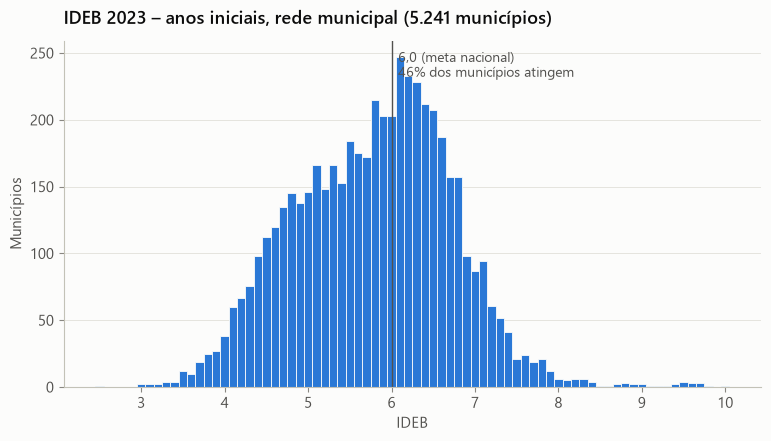

,count,mean,std,min,25%,50%,75%,max
IDEB 2023,"5.241,00","5,79","0,95","2,50","5,10","5,80","6,40","10,00"


In [10]:
ideb = treino['ideb']
pct_6 = (ideb >= 6).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(ideb, bins=np.arange(2.45, 10.06, 0.1), color=eg.AZUL, edgecolor=eg.FUNDO, linewidth=0.6)
ax.axvline(6, color=eg.TINTA_SEC, linewidth=1)
ax.text(6.08, ax.get_ylim()[1] * 0.97, f'6,0 (meta nacional)\n{pct_6:.0f}% dos municípios atingem',
        va='top', fontsize=10, color=eg.TINTA_SEC)
ax.set_title(f'IDEB 2023 – anos iniciais, rede municipal ({br(len(ideb))} municípios)')
ax.set_xlabel('IDEB')
ax.set_ylabel('Municípios')
ax.grid(axis='x', visible=False)
eg.salvar_figura(fig, '01_ideb_distribuicao_2023', FIGURAS)
plt.show()

ideb.describe().to_frame('IDEB 2023').T

### 5.1 Diferenças regionais

In [11]:
por_regiao = treino.groupby('regiao')['ideb'].agg(
    municipios='count', media='mean', mediana='median', desvio='std',
    pct_ideb_6=lambda s: (s >= 6).mean() * 100,
).sort_values('media')
por_regiao

,municipios,media,mediana,desvio,pct_ideb_6
regiao,,,,,
Norte,439,"4,77","4,80","0,68","4,56"
Nordeste,1763,"5,31","5,10","1,00","20,48"
Centro-Oeste,445,"5,93","6,00","0,72","50,79"
Sudeste,1576,"6,19","6,20","0,62","67,32"
Sul,1018,"6,35","6,40","0,68","73,48"


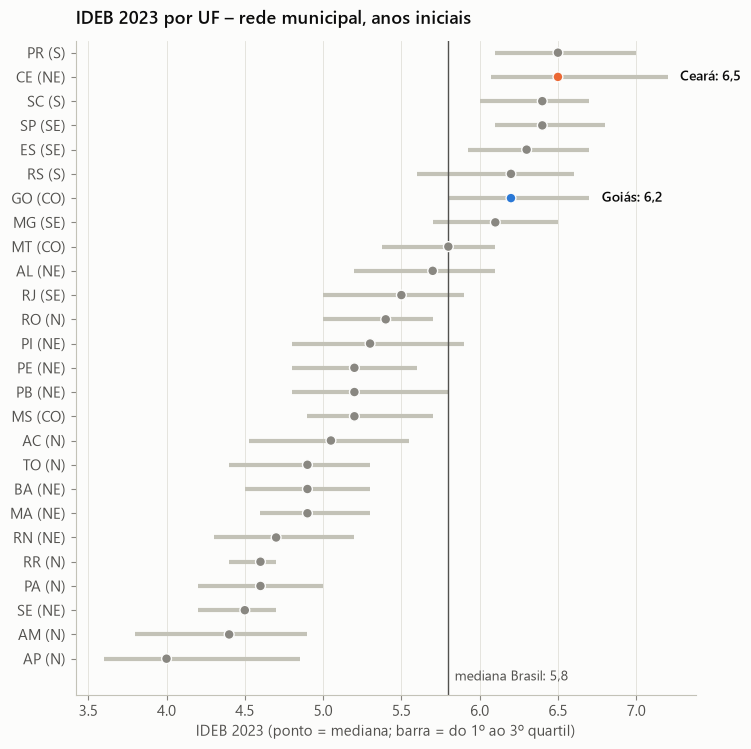

Goiás: 6ª maior mediana entre 26 UFs


In [12]:
SIGLA_REGIAO = {'Norte': 'N', 'Nordeste': 'NE', 'Sudeste': 'SE', 'Sul': 'S', 'Centro-Oeste': 'CO'}
por_uf = (treino.groupby(['sigla_uf', 'regiao'])['ideb']
          .agg(mediana='median', q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75),
               municipios='count')
          .reset_index().sort_values('mediana').reset_index(drop=True))
mediana_brasil = ideb.median()
DESTAQUES = {'GO': eg.AZUL, 'CE': eg.LARANJA}

fig, ax = plt.subplots(figsize=(8, 8.5))
y = np.arange(len(por_uf))
cores = [DESTAQUES.get(uf, eg.TINTA_MUDA) for uf in por_uf['sigla_uf']]
ax.hlines(y, por_uf['q1'], por_uf['q3'], color=eg.CINZA, linewidth=3)
ax.scatter(por_uf['mediana'], y, s=50, color=cores, zorder=3, edgecolor=eg.FUNDO, linewidth=1)
ax.axvline(mediana_brasil, color=eg.TINTA_SEC, linewidth=1)
ax.text(mediana_brasil + 0.04, -0.9, f'mediana Brasil: {br(mediana_brasil, 1)}',
        color=eg.TINTA_SEC, fontsize=10)
ax.set_yticks(y, [f"{uf} ({SIGLA_REGIAO[r]})" for uf, r in zip(por_uf['sigla_uf'], por_uf['regiao'])])
for i, linha in por_uf.iterrows():
    if linha['sigla_uf'] in DESTAQUES:
        nome = 'Goiás' if linha['sigla_uf'] == 'GO' else 'Ceará'
        ax.text(linha['q3'] + 0.08, i, f"{nome}: {br(linha['mediana'], 1)}", va='center',
                fontsize=10, color=eg.TINTA, fontweight='semibold')
ax.set_ylim(-1.5, len(por_uf) - 0.5)
ax.set_xlabel('IDEB 2023 (ponto = mediana; barra = do 1º ao 3º quartil)')
ax.set_title('IDEB 2023 por UF – rede municipal, anos iniciais')
ax.grid(axis='y', visible=False)
eg.salvar_figura(fig, '01_ideb_por_uf_2023', FIGURAS)
plt.show()

posicao_go = por_uf.sort_values('mediana', ascending=False)['sigla_uf'].tolist().index('GO') + 1
print(f'Goiás: {posicao_go}ª maior mediana entre {len(por_uf)} UFs')

A diferença regional é grande: a média do Norte fica cerca de 1,6 ponto abaixo da do Sul. Isso mostra que **a UF e a região precisam entrar no modelo** como contexto, e justifica o baseline pela média da UF: qualquer modelo precisa superar o que se consegue sabendo só o estado do município.

### 5.2 Ceará e Alagoas: valores muito altos

In [13]:
altos = treino[treino['ideb'] >= 8.5]
print(f'{len(altos)} municípios com IDEB >= 8,5 em 2023:', altos['sigla_uf'].value_counts().to_dict())

perfil = (treino.assign(grupo=np.where(treino['sigla_uf'].isin(['CE', 'AL']), 'CE e AL', 'Demais UFs'))
          .groupby('grupo')[['ideb', 'inse_medio_2015', 'pib_per_capita_2023', 'gasto_ef_por_aluno']]
          .median())
perfil.round(1)

28 municípios com IDEB >= 8,5 em 2023: {'CE': 18, 'AL': 6, 'PE': 1, 'SP': 1, 'PR': 1, 'RS': 1}


,ideb,inse_medio_2015,pib_per_capita_2023,gasto_ef_por_aluno
grupo,,,,
CE e AL,"6,20","41,80","16.434,80","11.508,10"
Demais UFs,"5,80","48,80","30.834,10","13.991,10"


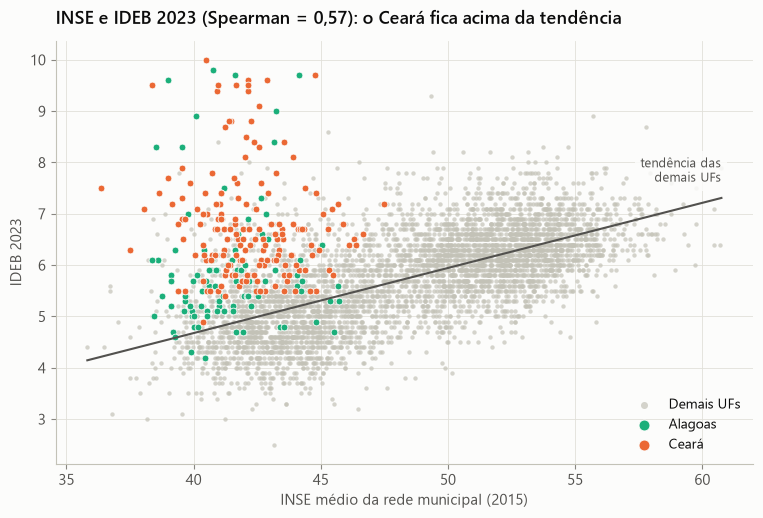

Ceará: 100% dos municípios acima da tendência, em média 1,82 ponto acima
Alagoas: 90% acima da tendência, em média 1,06


In [14]:
d = treino.dropna(subset=['inse_medio_2015'])
resto = d[~d['sigla_uf'].isin(['CE', 'AL'])]
ce = d[d['sigla_uf'] == 'CE']
al = d[d['sigla_uf'] == 'AL']
coef = np.polyfit(resto['inse_medio_2015'], resto['ideb'], 1)
desvio_ce = (ce['ideb'] - np.polyval(coef, ce['inse_medio_2015']))
desvio_al = (al['ideb'] - np.polyval(coef, al['inse_medio_2015']))
rho_inse = d['inse_medio_2015'].corr(d['ideb'], method='spearman')

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(resto['inse_medio_2015'], resto['ideb'], s=10, color=eg.CINZA, alpha=0.7, linewidths=0,
           label='Demais UFs')
ax.scatter(al['inse_medio_2015'], al['ideb'], s=24, color=eg.VERDE_AGUA, edgecolor=eg.FUNDO,
           linewidth=0.6, label='Alagoas')
ax.scatter(ce['inse_medio_2015'], ce['ideb'], s=24, color=eg.LARANJA, edgecolor=eg.FUNDO,
           linewidth=0.6, label='Ceará')
xs = np.linspace(d['inse_medio_2015'].min(), d['inse_medio_2015'].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color=eg.TINTA_SEC, linewidth=1.5)
ax.text(xs[-1], np.polyval(coef, xs[-1]) + 0.25, 'tendência das\ndemais UFs', ha='right', va='bottom',
        fontsize=9, color=eg.TINTA_SEC, bbox=dict(facecolor=eg.FUNDO, edgecolor='none', alpha=0.85))
ax.set_title(f'INSE e IDEB 2023 (Spearman = {br(rho_inse, 2)}): o Ceará fica acima da tendência')
ax.set_xlabel('INSE médio da rede municipal (2015)')
ax.set_ylabel('IDEB 2023')
ax.legend(loc='lower right', markerscale=1.6)
eg.salvar_figura(fig, '01_inse_vs_ideb_ceara', FIGURAS)
plt.show()

print(f'Ceará: {(desvio_ce > 0).mean() * 100:.0f}% dos municípios acima da tendência, '
      f'em média {br(desvio_ce.mean(), 2)} ponto acima')
print(f'Alagoas: {(desvio_al > 0).mean() * 100:.0f}% acima da tendência, em média {br(desvio_al.mean(), 2)}')

O Ceará tem nível socioeconômico e PIB per capita abaixo da média do país e, mesmo assim, um IDEB acima da tendência. Não é erro da base: é o padrão conhecido do estado, ligado à política estadual de alfabetização em colaboração com os municípios. Para o modelo, isso significa que **a UF carrega informação que nenhuma variável municipal mede**. Os valores entre 9 e 10 não serão removidos, mas vamos acompanhar o erro do modelo nesses municípios.

## 6. Relações com o IDEB (2023)

Usamos a correlação de Spearman porque várias variáveis são assimétricas (população, PIB, gasto) e a relação pode não ser linear. Totais absolutos (despesa em reais, PIB total, matrículas do EF, docentes) ficam fora: eles medem o tamanho do município, já representado pela população e pelas matrículas.

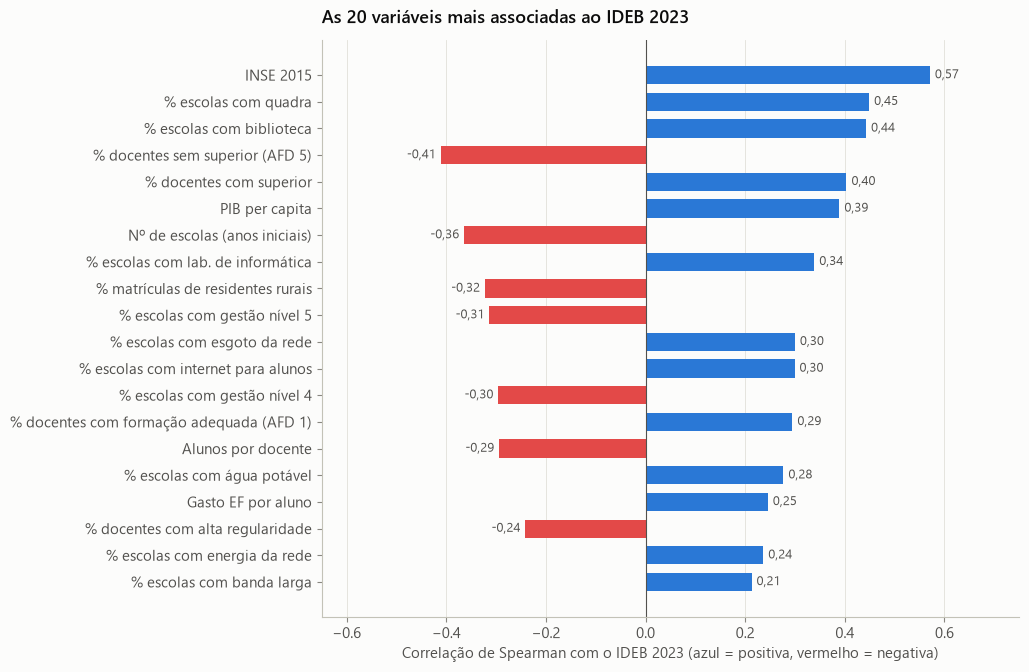

In [15]:
NAO_CANDIDATAS = ['ano', 'id_municipio', 'ideb', 'meta_ideb', 'n_linhas_siconfi_ef',
                  'desp_ensino_fundamental', 'desp_educacao_total', 'pib_2023', 'matriculas_ef',
                  'docentes_ai']
candidatas = [c for c in treino.select_dtypes('number').columns if c not in NAO_CANDIDATAS]
corr_ideb = treino[candidatas].corrwith(treino['ideb'], method='spearman')
top = corr_ideb.reindex(corr_ideb.abs().sort_values(ascending=False).index).head(20)[::-1]

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh([eg.rotulo(c) for c in top.index], top.values, height=0.68,
        color=[eg.POSITIVO if v > 0 else eg.NEGATIVO for v in top.values])
ax.axvline(0, color=eg.TINTA_SEC, linewidth=0.8)
for i, v in enumerate(top.values):
    ax.text(v + (0.01 if v > 0 else -0.01), i, br(v, 2), va='center', ha='left' if v > 0 else 'right',
            fontsize=9, color=eg.TINTA_SEC)
ax.set_xlim(-0.65, 0.75)
ax.set_xlabel('Correlação de Spearman com o IDEB 2023 (azul = positiva, vermelho = negativa)')
ax.set_title('As 20 variáveis mais associadas ao IDEB 2023')
ax.grid(axis='y', visible=False)
eg.salvar_figura(fig, '01_correlacoes_spearman_ideb', FIGURAS)
plt.show()

O padrão é coerente com a literatura: o **nível socioeconômico** (INSE, PIB per capita) é o fator mais associado, seguido de **formação docente** (% com superior, % sem superior) e **infraestrutura** (quadra, biblioteca, laboratório). Do lado negativo aparecem marcas de redes **rurais e dispersas** (muitas escolas, matrículas rurais, gestão mais complexa). O gasto por aluno tem associação positiva, mas moderada.

### 6.1 Gasto por aluno: associação ou contexto?

A pergunta central do gestor é se gastar mais está associado a um IDEB maior. Comparamos o IDEB por faixa de gasto **dentro** de cada faixa de nível socioeconômico. Os gastos implausíveis (abaixo de R$ 1 mil ou acima de R$ 60 mil) ficam fora deste gráfico.

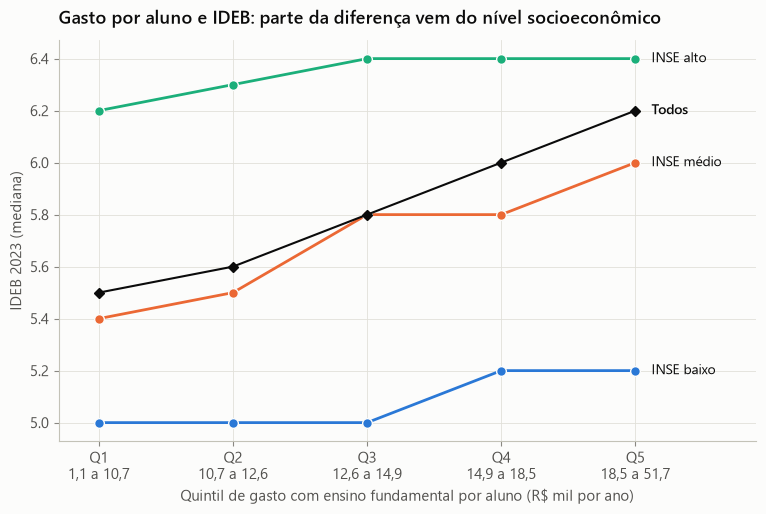

Composição de cada quintil de gasto por faixa de INSE (% das linhas):


faixa_inse,INSE baixo,INSE médio,INSE alto
quintil_gasto,,,
1,"46,00","30,00","23,00"
2,"42,00","27,00","30,00"
3,"36,00","31,00","32,00"
4,"28,00","36,00","36,00"
5,"14,00","41,00","45,00"


In [16]:
g = treino[treino['gasto_ef_por_aluno'].between(1000, 60000)].dropna(subset=['inse_medio_2015']).copy()
g['faixa_inse'] = pd.qcut(g['inse_medio_2015'], 3, labels=['INSE baixo', 'INSE médio', 'INSE alto'])
g['quintil_gasto'], limites = pd.qcut(g['gasto_ef_por_aluno'], 5, labels=False, retbins=True)

tab = g.pivot_table(index='quintil_gasto', columns='faixa_inse', values='ideb', aggfunc='median',
                    observed=True)
tab['Todos'] = g.groupby('quintil_gasto')['ideb'].median()

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(5)
for faixa, cor in zip(['INSE baixo', 'INSE médio', 'INSE alto'], [eg.AZUL, eg.LARANJA, eg.VERDE_AGUA]):
    ax.plot(x, tab[faixa], color=cor, marker='o', markersize=7, markeredgecolor=eg.FUNDO)
    ax.text(4.12, tab[faixa].iloc[-1], faixa, va='center', fontsize=10, color=eg.TINTA)
ax.plot(x, tab['Todos'], color=eg.TINTA, linewidth=1.5, marker='D', markersize=5)
ax.text(4.12, tab['Todos'].iloc[-1], 'Todos', va='center', fontsize=10, color=eg.TINTA,
        fontweight='semibold')
ax.set_xticks(x, [f'Q{i + 1}\n{br(limites[i] / 1000, 1)} a {br(limites[i + 1] / 1000, 1)}'
                  for i in range(5)])
ax.set_xlim(-0.3, 4.9)
ax.set_xlabel('Quintil de gasto com ensino fundamental por aluno (R$ mil por ano)')
ax.set_ylabel('IDEB 2023 (mediana)')
ax.set_title('Gasto por aluno e IDEB: parte da diferença vem do nível socioeconômico')
eg.salvar_figura(fig, '01_gasto_vs_ideb_por_inse', FIGURAS)
plt.show()

print('Composição de cada quintil de gasto por faixa de INSE (% das linhas):')
(pd.crosstab(g['quintil_gasto'] + 1, g['faixa_inse'], normalize='index') * 100).round(0)

Olhando todos os municípios juntos, o IDEB mediano sobe do 1º para o 5º quintil de gasto. Dentro de cada faixa de INSE a subida é menor, porque os municípios que mais gastam são também os de nível socioeconômico mais alto. É o exemplo direto de **confusão**: parte da associação entre gasto e IDEB é, na verdade, contexto.

Uma regressão simples, só exploratória, mede o quanto a associação encolhe quando o contexto entra:

In [17]:
g['log_gasto'] = np.log(g['gasto_ef_por_aluno'])
g['log_pib_pc'] = np.log(g['pib_per_capita_2023'])
especificacoes = {
    'Só gasto': 'ideb ~ log_gasto',
    '+ INSE e PIB per capita': 'ideb ~ log_gasto + inse_medio_2015 + log_pib_pc',
    '+ UF (comparação dentro do estado)': 'ideb ~ log_gasto + inse_medio_2015 + log_pib_pc + C(sigla_uf)',
}
linhas = []
for nome, formula in especificacoes.items():
    ajuste = smf.ols(formula, data=g).fit()
    linhas.append({'especificação': nome,
                   'coef. log(gasto)': ajuste.params['log_gasto'],
                   'IDEB associado a dobrar o gasto': ajuste.params['log_gasto'] * np.log(2),
                   'R²': ajuste.rsquared})
atenuacao = pd.DataFrame(linhas)
atenuacao.round(3)

,especificação,coef. log(gasto),IDEB associado a dobrar o gasto,R²
0,Só gasto,"0,59","0,41","0,05"
1,+ INSE e PIB per capita,"0,29","0,20","0,29"
2,+ UF (comparação dentro do estado),"0,16","0,11","0,53"


Dobrar o gasto por aluno está associado a uma diferença bem maior no IDEB quando não se controla nada do que quando se compara municípios de contexto parecido no mesmo estado. Mesmo o valor menor **não é efeito causal**: ainda faltam fatores não medidos (gestão, participação das famílias, políticas estaduais).

## 7. Correlação entre as features (multicolinearidade)

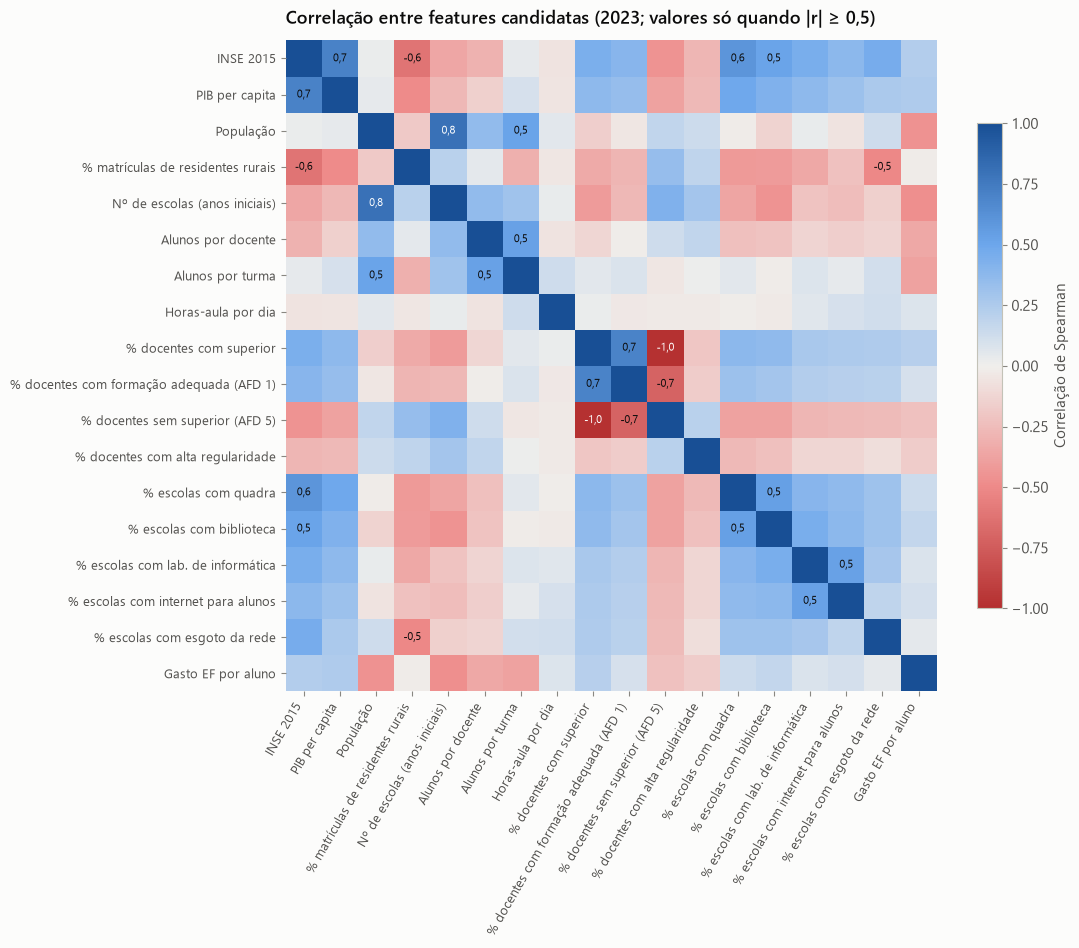

,,Spearman
dsu_ef_anos_iniciais,afd_ef_anos_iniciais_grupo_5,"-0,98"
populacao,n_escolas_ai,"0,80"
inse_medio_2015,pib_per_capita_2023,"0,71"
afd_ef_anos_iniciais_grupo_1,afd_ef_anos_iniciais_grupo_5,"-0,70"
dsu_ef_anos_iniciais,afd_ef_anos_iniciais_grupo_1,"0,70"
inse_medio_2015,pct_matr_residencia_rural,"-0,61"


In [18]:
SELECAO = ['inse_medio_2015', 'pib_per_capita_2023', 'populacao', 'pct_matr_residencia_rural',
           'n_escolas_ai', 'alunos_por_docente_ai', 'atu_ef_anos_iniciais', 'had_ef_anos_iniciais',
           'dsu_ef_anos_iniciais', 'afd_ef_anos_iniciais_grupo_1', 'afd_ef_anos_iniciais_grupo_5',
           'ird_alta', 'pct_esc_quadra', 'pct_esc_biblioteca', 'pct_esc_lab_informatica',
           'pct_esc_internet_alunos', 'pct_esc_esgoto_rede', 'gasto_ef_por_aluno']
m = treino[SELECAO].corr(method='spearman')
nomes = [eg.rotulo(c) for c in SELECAO]

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(m.values, cmap=eg.DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(nomes)), nomes, rotation=60, ha='right', fontsize=9)
ax.set_yticks(range(len(nomes)), nomes, fontsize=9)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        if i != j and abs(m.values[i, j]) >= 0.5:
            ax.text(j, i, br(m.values[i, j], 1), ha='center', va='center', fontsize=8,
                    color='white' if abs(m.values[i, j]) >= 0.75 else eg.TINTA)
ax.grid(False)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label='Correlação de Spearman')
ax.set_title('Correlação entre features candidatas (2023; valores só quando |r| ≥ 0,5)')
eg.salvar_figura(fig, '01_correlacoes_entre_features', FIGURAS)
plt.show()

pares = (m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
pares.rename('Spearman').to_frame()

Os pares mais correlacionados ficam nos mesmos blocos: INSE com PIB per capita, formação docente entre si, e infraestrutura com o caráter rural da rede. Para a Regressão Linear isso infla a variância dos coeficientes. No notebook 02 vamos resumir grupos (índices de infraestrutura e de formação) e conferir o VIF antes de interpretar os coeficientes.

## 8. Goiás em perspectiva

In [19]:
go = treino['sigla_uf'] == 'GO'
COLS_GO = ['ideb', 'gasto_ef_por_aluno', 'inse_medio_2015', 'pib_per_capita_2023', 'populacao',
           'dsu_ef_anos_iniciais', 'pct_esc_biblioteca', 'pct_esc_quadra']
tab_go = treino[COLS_GO].copy()
tab_go[['pct_esc_biblioteca', 'pct_esc_quadra']] *= 100  # fração -> %
comparacao = pd.DataFrame({'Goiás': tab_go[go].median(), 'Demais UFs': tab_go[~go].median()})
comparacao.loc['% municípios com IDEB >= 6'] = [(treino.loc[go, 'ideb'] >= 6).mean() * 100,
                                                (treino.loc[~go, 'ideb'] >= 6).mean() * 100]
comparacao.loc['municípios na base'] = [go.sum(), (~go).sum()]
comparacao.index = [eg.rotulo(c) for c in comparacao.index]
print('Medianas em 2023')
comparacao.round(1)

Medianas em 2023


,Goiás,Demais UFs
IDEB,"6,20","5,80"
Gasto EF por aluno,"18.370,20","13.692,20"
INSE 2015,"50,00","47,70"
PIB per capita,"38.864,00","28.572,30"
População,"7.583,50","12.225,00"
% docentes com superior,"96,50","94,10"
% escolas com biblioteca,"80,00","50,00"
% escolas com quadra,"50,00","42,90"
% municípios com IDEB >= 6,"68,80","45,00"
municípios na base,"240,00","5.001,00"


In [20]:
treino.loc[treino['id_municipio'] == 5208707,
           ['id_municipio', 'ideb', 'atu_ef_anos_iniciais', 'had_ef_anos_iniciais',
            'dsu_ef_anos_iniciais', 'gasto_ef_por_aluno', 'populacao']].set_index('id_municipio')

,ideb,atu_ef_anos_iniciais,had_ef_anos_iniciais,dsu_ef_anos_iniciais,gasto_ef_por_aluno,populacao
id_municipio,,,,,,
5208707,"6,50","24,50","5,20","96,30","13.698,11","1.437.366,00"


Goiás está acima da mediana nacional, gasta mais por aluno e tem INSE mais alto que o restante do país. O estudo de caso no notebook 04 vai olhar, dentro de Goiás, quais municípios ficam abaixo do IDEB esperado para o seu perfil.

## 9. Conclusões da exploração e decisões para a preparação

**O que a exploração mostrou (safra 2023)**

| Tema | Achado |
|---|---|
| Base | 5.241 municípios em 26 UFs, sem chave duplicada e sem nenhuma coluna ligada ao cálculo do IDEB. 329 municípios (5,9%) ficaram sem IDEB da rede municipal. |
| Alvo | Média 5,79, mediana 5,8, desvio 0,95. 46% dos municípios atingem 6,0. |
| Região e UF | Média de 4,77 no Norte e 6,35 no Sul. A UF explica boa parte da diferença, o que justifica o baseline pela média da UF. |
| Fatores mais associados | INSE (Spearman 0,57), quadra (0,45), biblioteca (0,44), docentes sem superior (−0,41), docentes com superior (0,40), PIB per capita (0,39). Do lado negativo, marcas de rede rural e dispersa. |
| Gasto por aluno | Associação moderada (0,25) e confundida com o contexto: dobrar o gasto acompanha +0,41 ponto sem controles, +0,20 com INSE e PIB e +0,11 dentro da mesma UF. |
| Ceará e Alagoas | 24 dos 28 municípios com IDEB ≥ 8,5 são do CE ou de AL. Todos os municípios do CE com INSE ficam acima da tendência nacional (+1,82 ponto em média). |
| Qualidade | INSE ausente em 4,5% (20,7% no RS). Gasto ausente em 0,65% em 2023 e 4,1% em 2025 (Siconfi 2025 incompleto). 15 gastos por aluno implausíveis. Sem duplicidade no Siconfi. PIB em reais. |
| Redundâncias | AFD, IED, ICG e IRD somam 100% cada. % com superior × % sem superior: −0,98. População × nº de escolas: 0,80. INSE × PIB per capita: 0,71. |

**Decisões para o notebook 02**
1. Gasto por aluno abaixo de R$ 1 mil ou acima de R$ 60 mil vira ausente (erro de declaração). Os demais extremos serão limitados aos percentis 1% e 99% do treino, dentro do pipeline.
2. Converter as colunas `pct_esc_*` de fração (0 a 1) para percentual (0 a 100), para ficarem na mesma escala das demais.
3. Resumir os grupos que somam 100%: % de formação adequada (AFD 1) e médias ponderadas pelo nível para IED, ICG e IRD. Retirar % sem superior (espelho de % com superior).
4. Aplicar log em população, PIB per capita e gasto por aluno. Trocar o número de escolas por alunos por escola, que mede a dispersão da rede sem repetir a população.
5. Manter os municípios com IDEB entre 9 e 10 e acompanhar o erro do modelo neles.
6. Testar no notebook 03 se a UF (em vez da região) melhora o modelo, já que o efeito do Ceará é estadual.